## Step 1 — Data Collection
The generated retail sales dataset includes transaction dates, categories, regions, quantities, prices, discounts, and ratings. Missing values and unusually large values were intentionally introduced to demonstrate preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
df = pd.read_csv("retail_sales_raw.csv", parse_dates=["Date"])
print("Dataset shape:", df.shape)
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset shape: (240, 8)


,Order_ID,Date,Category,Region,Units_Sold,Unit_Price,Discount_Pct,Customer_Rating
0,ORD-0001,2025-01-01,Sports,South,8.0,99.05,5,5
1,ORD-0002,2025-01-02,Clothing,West,1.0,50.02,20,5
2,ORD-0003,2025-01-03,Electronics,South,3.0,152.32,0,4
3,ORD-0004,2025-01-04,Clothing,North,5.0,36.74,10,5
4,ORD-0005,2025-01-05,Clothing,North,11.0,38.30,10,4


**SCREENSHOT 01:** Capture the output above showing the first five rows.

## Step 2 — Data Visualization
Visualizations use a temporary analysis copy with missing numeric values filled by category medians. The original data remain unchanged for the preprocessing demonstrations.

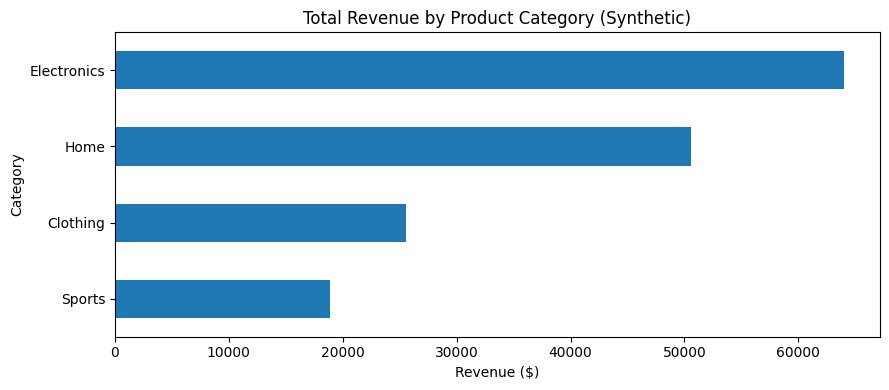

Insight: Category totals reflect both prices and quantities; compare categories rather than individual transactions.


In [2]:
viz = df.copy()
for col in ["Units_Sold", "Unit_Price"]:
    viz[col] = viz[col].fillna(viz.groupby("Category")[col].transform("median"))
viz["Revenue"] = viz["Units_Sold"] * viz["Unit_Price"] * (1-viz["Discount_Pct"]/100)
fig, ax = plt.subplots(figsize=(9,4))
viz.groupby("Category")["Revenue"].sum().sort_values().plot.barh(ax=ax)
ax.set(title="Total Revenue by Product Category (Synthetic)",xlabel="Revenue ($)",ylabel="Category")
plt.tight_layout(); plt.show()
print("Insight: Category totals reflect both prices and quantities; compare categories rather than individual transactions.")

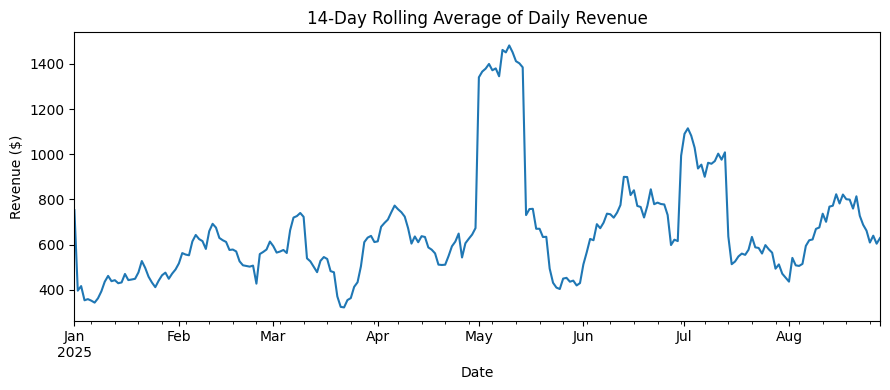

Insight: The smoothed series shows variation over time; synthetic dates do not establish real seasonal patterns.


In [3]:
daily = viz.groupby("Date")["Revenue"].sum()
fig, ax=plt.subplots(figsize=(9,4))
daily.rolling(14,min_periods=1).mean().plot(ax=ax)
ax.set(title="14-Day Rolling Average of Daily Revenue",ylabel="Revenue ($)",xlabel="Date")
plt.tight_layout();plt.show()
print("Insight: The smoothed series shows variation over time; synthetic dates do not establish real seasonal patterns.")

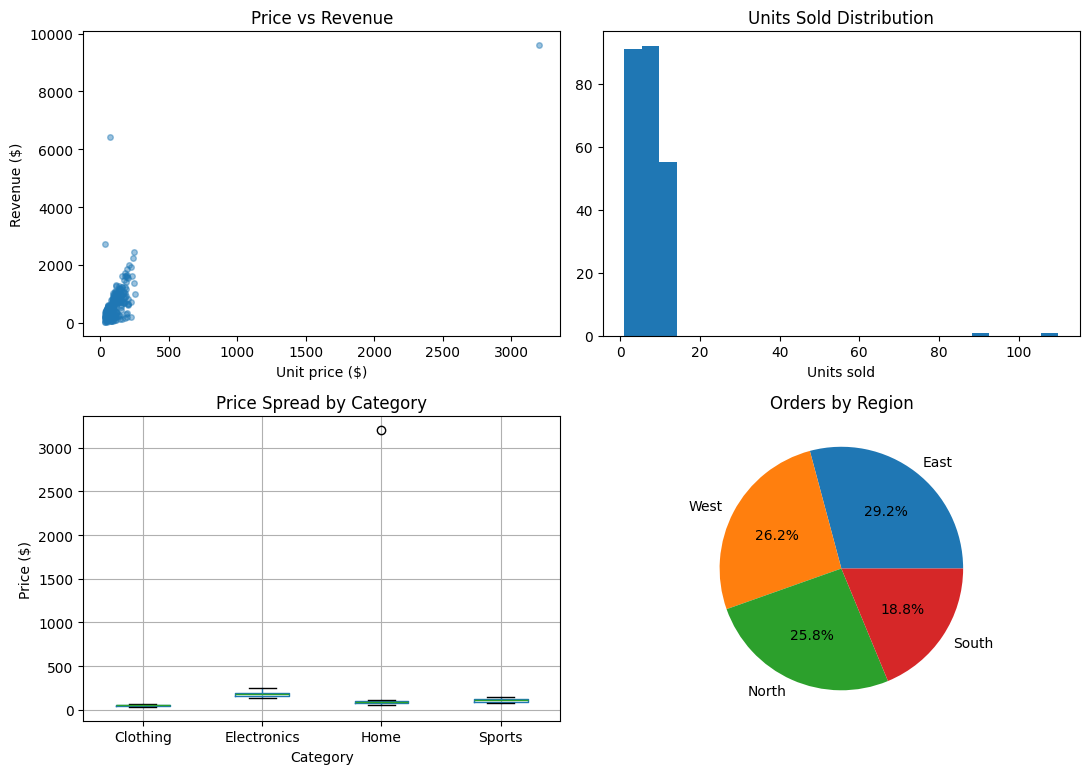

Insights: The histogram and boxplot reveal extreme values; scatterplot shows transaction revenue depends on price and units; pie chart compares region shares.


In [3]:
fig,axs=plt.subplots(2,2,figsize=(11,8))
axs[0,0].scatter(viz["Unit_Price"],viz["Revenue"],alpha=.45,s=16);axs[0,0].set(xlabel="Unit price ($)",ylabel="Revenue ($)",title="Price vs Revenue")
axs[0,1].hist(viz["Units_Sold"],bins=25);axs[0,1].set(title="Units Sold Distribution",xlabel="Units sold")
viz.boxplot(column="Unit_Price",by="Category",ax=axs[1,0]);axs[1,0].set(title="Price Spread by Category",xlabel="Category",ylabel="Price ($)")
viz["Region"].value_counts().plot.pie(ax=axs[1,1],autopct="%1.1f%%");axs[1,1].set(title="Orders by Region",ylabel="")
fig.suptitle("");plt.tight_layout();plt.show()
print("Insights: The histogram and boxplot reveal extreme values; scatterplot shows transaction revenue depends on price and units; pie chart compares region shares.")

**SCREENSHOT 02 and 03:** Capture at least two charts and their printed insight descriptions. The notebook provides six chart types.

## Step 3 — Data Preprocessing
### 3.1 Missing Values

In [4]:
print("BEFORE — missing values per column:")
display(df.isna().sum().to_frame("Missing_Count"));display(df[df.isna().any(axis=1)].head(10))
clean = df.copy()
for col in ["Units_Sold","Unit_Price"]:
    clean[col] = clean[col].fillna(clean.groupby("Category")[col].transform("median"))
print("AFTER — missing values per column:")
display(clean.isna().sum().to_frame("Missing_Count"));display(clean.loc[df.isna().any(axis=1)].head(10))

BEFORE — missing values per column:


,Missing_Count
Order_ID,0
Date,0
Category,0
Region,0
Units_Sold,3
Unit_Price,3
Discount_Pct,0
Customer_Rating,0


,Order_ID,Date,Category,Region,Units_Sold,Unit_Price,Discount_Pct,Customer_Rating
8,ORD-0009,2025-01-09,Sports,West,NaN,107.56,15,4
16,ORD-0017,2025-01-17,Home,North,1.0,NaN,15,4
42,ORD-0043,2025-02-12,Clothing,West,NaN,37.01,15,1
85,ORD-0086,2025-03-27,Electronics,West,7.0,NaN,15,4
131,ORD-0132,2025-05-12,Clothing,West,NaN,57.24,10,3
198,ORD-0199,2025-07-18,Clothing,North,7.0,NaN,20,3


AFTER — missing values per column:


,Missing_Count
Order_ID,0
Date,0
Category,0
Region,0
Units_Sold,0
Unit_Price,0
Discount_Pct,0
Customer_Rating,0


,Order_ID,Date,Category,Region,Units_Sold,Unit_Price,Discount_Pct,Customer_Rating
8,ORD-0009,2025-01-09,Sports,West,7.0,107.56,15,4
16,ORD-0017,2025-01-17,Home,North,1.0,91.14,15,4
42,ORD-0043,2025-02-12,Clothing,West,6.0,37.01,15,1
85,ORD-0086,2025-03-27,Electronics,West,7.0,176.69,15,4
131,ORD-0132,2025-05-12,Clothing,West,6.0,57.24,10,3
198,ORD-0199,2025-07-18,Clothing,North,7.0,50.26,20,3


**SCREENSHOT 04:** Capture the missing-value counts and before/after affected rows. Category medians preserve category-specific typical values.

### 3.2 Outlier Detection and Removal Using IQR

In [6]:
q1=clean["Units_Sold"].quantile(.25);q3=clean["Units_Sold"].quantile(.75);iqr=q3-q1
lower=q1-1.5*iqr;upper=q3+1.5*iqr
print(f"Units_Sold: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, lower={lower:.2f}, upper={upper:.2f}")
mask=(clean["Units_Sold"]<lower)|(clean["Units_Sold"]>upper)
print("Identified outliers:");display(clean.loc[mask,["Order_ID","Units_Sold","Category"]])
print("Before:",len(clean));clean=clean.loc[~mask].copy();print("After:",len(clean))
display(clean[["Order_ID","Units_Sold","Category"]].head())

Units_Sold: Q1=4.00, Q3=9.00, IQR=5.00, lower=-3.50, upper=16.50
Identified outliers:


,Order_ID,Units_Sold,Category
55,ORD-0056,90.0,Clothing
180,ORD-0181,110.0,Home


Before: 240
After: 238


,Order_ID,Units_Sold,Category
0,ORD-0001,8.0,Sports
1,ORD-0002,1.0,Clothing
2,ORD-0003,3.0,Electronics
3,ORD-0004,5.0,Clothing
4,ORD-0005,11.0,Clothing


**SCREENSHOT 05:** Capture the quartiles, IQR, thresholds, identified outliers, and reduced row count. This exercise removes outliers in Units_Sold only; other columns may retain extreme values.

### 3.3 Data Reduction: Sampling and Column Elimination

In [5]:
print("BEFORE reduction:",clean.shape);display(clean.head())
sample=clean.sample(frac=.60,random_state=634).drop(columns=["Customer_Rating"])
print("AFTER 60% sampling and dropping Customer_Rating:",sample.shape);display(sample.head())

BEFORE reduction: (240, 8)


,Order_ID,Date,Category,Region,Units_Sold,Unit_Price,Discount_Pct,Customer_Rating
0,ORD-0001,2025-01-01,Sports,South,8.0,99.05,5,5
1,ORD-0002,2025-01-02,Clothing,West,1.0,50.02,20,5
2,ORD-0003,2025-01-03,Electronics,South,3.0,152.32,0,4
3,ORD-0004,2025-01-04,Clothing,North,5.0,36.74,10,5
4,ORD-0005,2025-01-05,Clothing,North,11.0,38.30,10,4


AFTER 60% sampling and dropping Customer_Rating: (144, 7)


,Order_ID,Date,Category,Region,Units_Sold,Unit_Price,Discount_Pct
30,ORD-0031,2025-01-31,Electronics,East,2.0,195.88,15
141,ORD-0142,2025-05-22,Clothing,South,5.0,56.52,0
9,ORD-0010,2025-01-10,Home,North,10.0,90.96,10
237,ORD-0238,2025-08-26,Home,West,7.0,72.59,10
73,ORD-0074,2025-03-15,Home,East,9.0,104.46,5


**SCREENSHOT 06:** Capture before/after shapes and samples. The sample is a separate reduced view; the full cleaned dataset is retained for subsequent analysis.

### 3.4 Scaling and Discretization

In [6]:
print("BEFORE:");display(clean[["Unit_Price","Units_Sold"]].head())
scaled=clean.copy()
min_p,max_p=scaled["Unit_Price"].min(),scaled["Unit_Price"].max()
scaled["Unit_Price_MinMax"]=(scaled["Unit_Price"]-min_p)/(max_p-min_p)
scaled["Sales_Volume_Band"]=pd.cut(scaled["Units_Sold"],bins=[-np.inf,3,7,np.inf],labels=["Low","Medium","High"])
print("AFTER:");display(scaled[["Unit_Price","Unit_Price_MinMax","Units_Sold","Sales_Volume_Band"]].head(10))
print("Scaled min/max:",scaled["Unit_Price_MinMax"].min(),scaled["Unit_Price_MinMax"].max())

BEFORE:


,Unit_Price,Units_Sold
0,99.05,8.0
1,50.02,1.0
2,152.32,3.0
3,36.74,5.0
4,38.30,11.0


AFTER:


,Unit_Price,Unit_Price_MinMax,Units_Sold,Sales_Volume_Band
0,99.05,0.020649,8.0,High
1,50.02,0.005164,1.0,Low
2,152.32,0.037472,3.0,Low
3,36.74,0.000970,5.0,Medium
4,38.30,0.001462,11.0,High
5,44.25,0.003341,8.0,High
6,57.09,0.007397,6.0,Medium
7,52.31,0.005887,10.0,High
8,107.56,0.023336,7.0,Medium
9,90.96,0.018094,10.0,High


Scaled min/max: 0.0 1.0


**SCREENSHOT 07:** Capture before/after scaling and discretization. Min–max scaling is sensitive to extreme values.

## Step 4 — Statistical Analysis
### 4.1 General Overview

In [9]:
clean.info();display(clean.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
Index: 238 entries, 0 to 239
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         238 non-null    object        
 1   Date             238 non-null    datetime64[ns]
 2   Category         238 non-null    object        
 3   Region           238 non-null    object        
 4   Units_Sold       238 non-null    float64       
 5   Unit_Price       238 non-null    float64       
 6   Discount_Pct     238 non-null    int64         
 7   Customer_Rating  238 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 16.7+ KB


,Order_ID,Date,Category,Region,Units_Sold,Unit_Price,Discount_Pct,Customer_Rating
count,238,238,238,238,238.000000,238.000000,238.000000,238.000000
unique,238,NaN,4,4,NaN,NaN,NaN,NaN
top,ORD-0001,NaN,Clothing,East,NaN,NaN,NaN,NaN
freq,1,NaN,77,69,NaN,NaN,NaN,NaN
mean,NaN,2025-04-30 12:24:12.100840448,NaN,NaN,6.436975,115.419454,10.084034,3.810924
min,NaN,2025-01-01 00:00:00,NaN,NaN,1.000000,33.670000,0.000000,1.000000
25%,NaN,2025-03-02 06:00:00,NaN,NaN,4.000000,56.827500,5.000000,3.000000
50%,NaN,2025-04-30 12:00:00,NaN,NaN,6.500000,91.150000,10.000000,4.000000
75%,NaN,2025-06-28 18:00:00,NaN,NaN,9.000000,141.425000,15.000000,5.000000
max,NaN,2025-08-28 00:00:00,NaN,NaN,11.000000,3200.000000,20.000000,5.000000


**SCREENSHOT 08:** Capture `.info()` and `.describe()` outputs.

### 4.2 Central Tendency

In [7]:
numeric=clean.select_dtypes(include="number")
central=pd.DataFrame({"Minimum":numeric.min(),"Maximum":numeric.max(),"Mean":numeric.mean(),"Median":numeric.median(),"Mode":numeric.mode().iloc[0]})
display(central.round(3))

,Minimum,Maximum,Mean,Median,Mode
Units_Sold,1.00,110.0,7.217,7.00,10.00
Unit_Price,33.67,3200.0,114.910,91.13,44.25
Discount_Pct,0.00,20.0,10.146,10.00,0.00
Customer_Rating,1.00,5.0,3.817,4.00,4.00


**SCREENSHOT 09:** Capture minimum, maximum, mean, median, and mode.

### 4.3 Dispersion

In [11]:
dispersion=pd.DataFrame({"Range":numeric.max()-numeric.min(),"Q1":numeric.quantile(.25),"Q2_Median":numeric.quantile(.5),"Q3":numeric.quantile(.75),"IQR":numeric.quantile(.75)-numeric.quantile(.25),"Variance":numeric.var(),"Std_Dev":numeric.std()})
display(dispersion.round(3))

,Range,Q1,Q2_Median,Q3,IQR,Variance,Std_Dev
Units_Sold,10.00,4.000,6.50,9.000,5.000,9.319,3.053
Unit_Price,3166.33,56.828,91.15,141.425,84.598,43179.779,207.797
Discount_Pct,20.00,5.000,10.00,15.000,10.000,55.900,7.477
Customer_Rating,4.00,3.000,4.00,5.000,2.000,1.285,1.133


**SCREENSHOT 10:** Capture range, quartiles, IQR, variance, and standard deviation. Pandas uses sample variance and standard deviation by default.

### 4.4 Correlation Analysis

,Units_Sold,Unit_Price,Discount_Pct,Customer_Rating
Units_Sold,1.000,-0.049,0.075,0.010
Unit_Price,-0.049,1.000,-0.081,0.026
Discount_Pct,0.075,-0.081,1.000,-0.017
Customer_Rating,0.010,0.026,-0.017,1.000


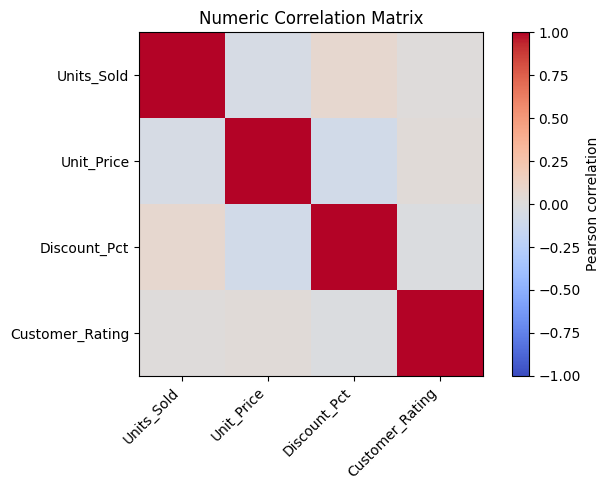

Interpretation: Correlation describes linear association, not causation. Numeric columns here exclude identifiers and dates.


In [8]:
corr=numeric.corr();display(corr.round(3))
fig,ax=plt.subplots(figsize=(7,5));im=ax.imshow(corr,cmap="coolwarm",vmin=-1,vmax=1)
ax.set_xticks(range(len(corr.columns)),corr.columns,rotation=45,ha="right");ax.set_yticks(range(len(corr.index)),corr.index)
fig.colorbar(im,ax=ax,label="Pearson correlation");ax.set_title("Numeric Correlation Matrix");plt.tight_layout();plt.show()
print("Interpretation: Correlation describes linear association, not causation. Numeric columns here exclude identifiers and dates.")

**SCREENSHOT 11:** Capture `.corr()` table (heatmap optional).

## Export and Final Reflection

In [9]:
clean.to_csv("retail_sales_cleaned.csv",index=False)
scaled.to_csv("retail_sales_scaled.csv",index=False)
print("Saved retail_sales_cleaned.csv and retail_sales_scaled.csv")
print("Cleaned rows:",len(clean),"| Removed outliers:",len(df)-len(clean))

Saved retail_sales_cleaned.csv and retail_sales_scaled.csv
Cleaned rows: 240 | Removed outliers: 0


### Reflection
The lab demonstrated exploratory visualization, category-wise median imputation, IQR-based outlier removal, reproducible random sampling, feature elimination, min–max scaling, discretization, and descriptive statistics. Synthetic extreme values highlight why preprocessing decisions should be documented. The outlier rule was applied to quantity only, and conclusions are illustrative rather than representative of real retail operations.